# Pandas samples


In [1]:
from pandas import DataFrame

data_persons = {
    "ID": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13],
    "Name": ["Alice", "Bob", "Charlie", "Diana", "Ethan", "Fiona", "George", "Hannah", "Isaac", "Julia", "Kevin", "Laura", "Michael"],
    "Age": [25, 30, 35, 28, 32, 27, 41, 36, 24, 33, 29, 38, 31],
    "Sex": ["F", "M", "M", "F", "M", "F", "M", "F", "M", "F", "M", "F", "M"],
    "City": ["New York", "Los Angeles", "Chicago", "Boston", "New York", "Los Angeles", "Chicago", "Boston", "New York", "Los Angeles", "Chicago", "Boston", "New York"]
}

data_products = {
    "ID": [1, 2, 3, 4, 5],
    "Product": ["Laptop", "Smartphone", "Tablet", "Monitor", "Keyboard"],
    "Price": [1200, 800, 400, 300, 100]
}

data_orders = {
    "OrderID": [1, 2, 3, 4, 5],
    "PersonID": [1, 2, 3, 4, 5]
}

data_order_items = {
    "OrderID": [1, 1, 1, 2, 3, 4, 4, 5, 5],
    "ProductID": [1, 2, 3, 4, 5, 1, 3, 2, 4],
    "Quantity": [1, 2, 1, 3, 2, 1, 2, 1, 2]
}

df_persons = DataFrame(data_persons)
df_products = DataFrame(data_products)
df_orders = DataFrame(data_orders)
df_order_items = DataFrame(data_order_items)

# df_persons.head()

print("Avg. persons age:", df_persons["Age"].mean())

print("Avg. persons age by city:")
print(df_persons.groupby("City")["Age"].mean())

print("Avg. persons age by sex:")
print(df_persons.groupby("Sex")["Age"].mean())

print("Avg. persons age by city and sex:")
print(df_persons.groupby(["City", "Sex"])["Age"].mean())

print("Count by city and sex:")
print(df_persons.groupby(["City", "Sex"]).count())


Avg. persons age: 31.46153846153846
Avg. persons age by city:
City
Boston         34.0
Chicago        35.0
Los Angeles    30.0
New York       28.0
Name: Age, dtype: float64
Avg. persons age by sex:
Sex
F    31.166667
M    31.714286
Name: Age, dtype: float64
Avg. persons age by city and sex:
City         Sex
Boston       F      34.0
Chicago      M      35.0
Los Angeles  F      30.0
             M      30.0
New York     F      25.0
             M      29.0
Name: Age, dtype: float64
Count by city and sex:
                 ID  Name  Age
City        Sex               
Boston      F     3     3    3
Chicago     M     3     3    3
Los Angeles F     2     2    2
            M     1     1    1
New York    F     1     1    1
            M     3     3    3


   OrderID  PersonID  total_price     Name  Age Sex         City
0        1         1         3200    Alice   25   F     New York
1        2         2          900      Bob   30   M  Los Angeles
2        3         3          200  Charlie   35   M      Chicago
3        4         4         2000    Diana   28   F       Boston
4        5         5         1400    Ethan   32   M     New York


<Axes: >

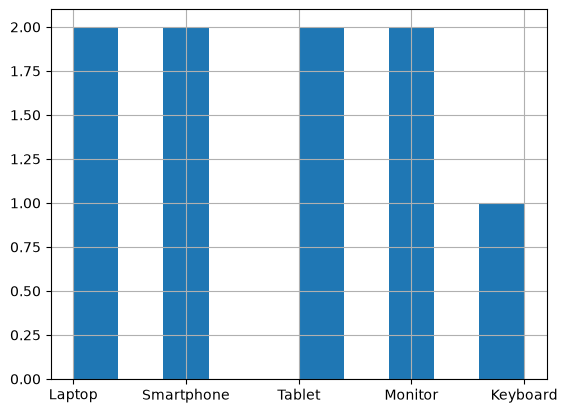

In [9]:
# Joins
# print("Orders with person details:")
# print(df_orders.merge(df_persons, left_on="PersonID", right_on="ID"))

# print("Order items with product details:")
# print(df_order_items.merge(df_products, left_on="ProductID", right_on="ID"))

df_items_price = \
    df_order_items.merge(df_products, left_on="ProductID", right_on="ID")

df_items_price["total_price"] = df_items_price["Price"] * df_order_items["Quantity"]

df_order_total_price = DataFrame(df_items_price.groupby("OrderID")["total_price"].sum()).reset_index()

df_order_total_price = \
    df_order_total_price \
        .merge(df_orders, left_on="OrderID", right_on="OrderID") \
            .merge(df_persons, left_on="PersonID", right_on="ID")

print(df_order_total_price.select("OrderID", "PersonID", "total_price", "Name", "Age", "Sex", "City"))

# df_order_total_price.plot.scatter(x="total_price", y="Age", title="Order Total Price vs. Age")

df_order_items.merge(df_products, left_on="ProductID", right_on="ID")["Product"].hist()
